# Three regimes and shared-history forecasting evidence

**Research question.** How do annual allocations and downside risk differ when
both market dynamics and the forecasting model are made explicit?

This notebook reads explicitly identified, completed annual runs. It does not
depend on another notebook's live kernel. Targets match between strategies within
each fitted model; they can differ between models and oracle regimes.

The top panels compare matched models across oracle regimes. The bottom panels
hold the dynamic oracle fixed and compare its matched volatility forecaster with
a Gaussian forecaster on the same observed history and held-out futures.


### Read explicit evidence references

Every run is named by its immutable directory ID. No automatic latest-run lookup occurs.

**Inputs:** project root, reference_runs.json.  
**Created / outputs:** root, references.  
**Canonical implementation:** `annual.comparison.load_comparison`.

In [1]:
# M5.COMPARISON.REFERENCES — Read explicit evidence references
# Inputs: project root, reference_runs.json
# Created: root, references
import os
import json
import matplotlib.pyplot as plt
from IPython.display import display
from thesis_portfolio.annual.config import project_root
from thesis_portfolio.annual.comparison import load_comparison, regime_dashboard
from thesis_portfolio.annual.studies import study_directory, save_study
root = project_root(os.environ.get('THESIS_PROJECT_ROOT'))
references = json.loads((root/'documentation/implementation_tasks/reference_runs.json').read_text())
display(references)

{'gaussian': 'm05-gaussian-baseline-provisional_pilot-20261127T163448-2a76f04c',
 'garch': 'm05-garch-baseline-provisional_pilot-20261127T163455-9c7a1345',
 'gjr': 'm05-gjr-baseline-provisional_pilot-20261127T163503-222a7cac'}

### Validate and combine annual results

The loader requires matching histories, horizons, policies and scenario counts. Both oracle and forecast-family labels remain attached.

**Inputs:** references.  
**Created / outputs:** comparison.  
**Canonical implementation:** `annual.comparison.load_comparison`.

In [2]:
# M5.COMPARISON.LOAD — Validate and combine annual results
# Inputs: references
# Created: comparison
comparison = load_comparison(root,references)
display(comparison[['oracle','forecast_family','strategy','confidence','fitted_target','oracle_mean','oracle_cvar']])

,oracle,forecast_family,strategy,confidence,fitted_target,oracle_mean,oracle_cvar
0,gaussian,gaussian,ERC,0.95,0.118458,0.091093,0.174132
1,gaussian,gaussian,ERC,0.99,0.118458,0.091093,0.230617
2,gaussian,gaussian,Markowitz,0.95,0.118458,0.065432,0.158976
3,gaussian,gaussian,Markowitz,0.99,0.118458,0.065432,0.211950
4,gaussian,gaussian,CVaR,0.95,0.118458,0.065734,0.158859
5,gaussian,gaussian,CVaR,0.99,0.118458,0.065734,0.211787
6,garch,garch,ERC,0.95,-0.021599,0.088306,0.168190
7,garch,garch,ERC,0.99,-0.021599,0.088306,0.229166
8,garch,garch,Markowitz,0.95,-0.021599,0.081170,0.164158
9,garch,garch,Markowitz,0.99,-0.021599,0.081170,0.221603


### Inspect the expected-return controls

There is one target within each fitted model/run, not a universal percentage across all rows.

**Inputs:** comparison.  
**Created / outputs:** target table.  
**Canonical implementation:** `annual.comparison.load_comparison`.

In [3]:
# M5.COMPARISON.TARGETS — Inspect the expected-return controls
# Inputs: comparison
# Created: target table
targets = comparison[['oracle','forecast_family','fitted_target']].drop_duplicates()
display(targets)

,oracle,forecast_family,fitted_target
0,gaussian,gaussian,0.118458
6,garch,garch,-0.021599
12,garch,gaussian,-0.002900
18,gjr,gjr,0.193804
24,gjr,gaussian,0.197864


### Display the three-regime dashboard

These conditional results describe the saved histories. They do not establish an across-history ranking or isolate asymmetry when persistence also differs.

**Inputs:** comparison.  
**Created / outputs:** dashboard.  
**Canonical implementation:** `annual.comparison.regime_dashboard`.

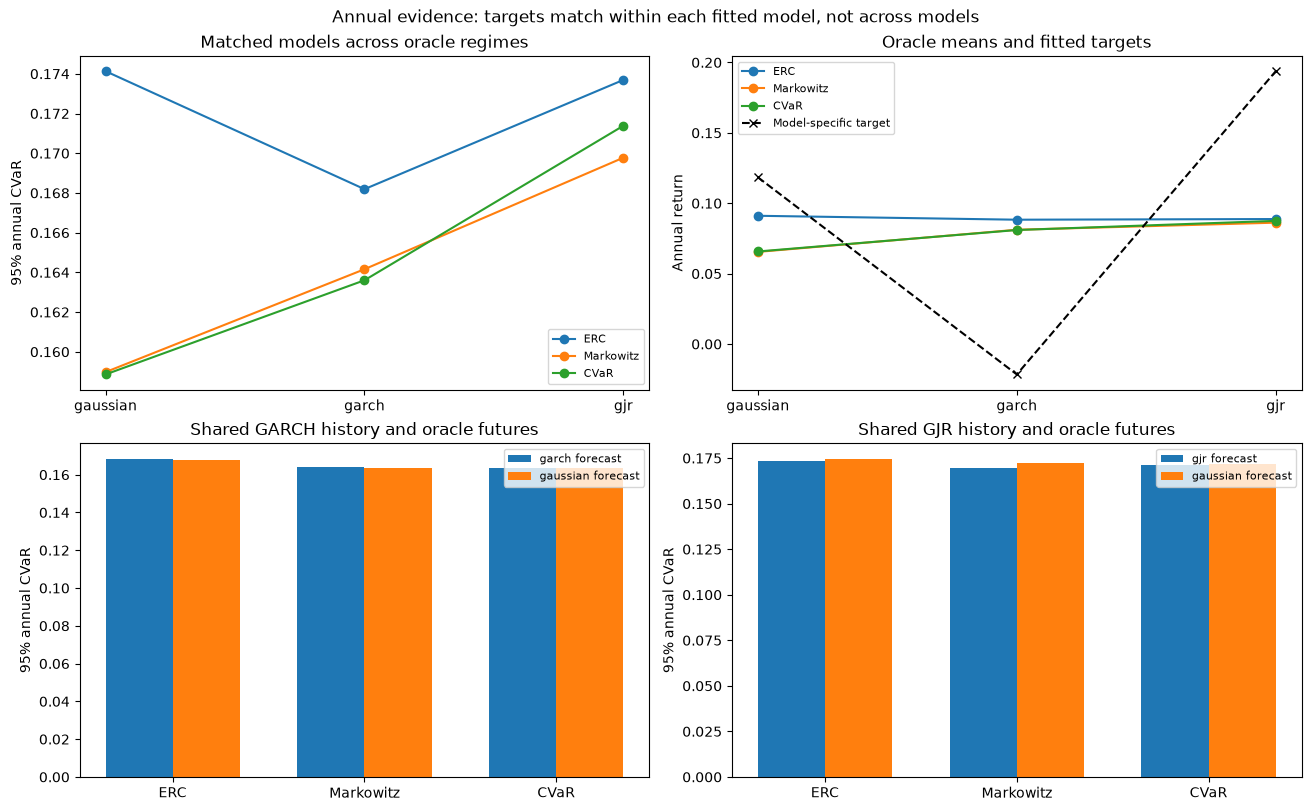

In [4]:
# M5.COMPARISON.DASHBOARD — Display the three-regime dashboard
# Inputs: comparison
# Created: dashboard
dashboard = regime_dashboard(comparison)
plt.show()

### Save comparison evidence and provenance

The manifest records explicit source run IDs. Reproduction requires those saved artifacts or their recorded generating configurations.

**Inputs:** comparison, references, dashboard.  
**Created / outputs:** comparison study.  
**Canonical implementation:** `annual.studies.save_study`.

In [5]:
# M5.COMPARISON.SAVE — Save comparison evidence and provenance
# Inputs: comparison, references, dashboard
# Created: comparison study
path = study_directory(root,'three-regime-comparison')
save_study(path,{'comparison':comparison,'targets':targets},{'source_run_ids':references,'return_control':'within fitted model only'})
dashboard.savefig(path/'three_regime_dashboard.png',dpi=150,bbox_inches='tight')
print(path)

/Users/morty/Documents/ChatGPT/Thesis Under Prof. Rubtsov/results/m05-three-regime-comparison-20261127T163643-e5d4d826


## Discussion

Read oracle mean and downside risk together when targets change. Cross-regime
differences combine changes in market dynamics with estimation and target effects.
Shared-history Gaussian comparisons hold the oracle outcomes fixed, but their
fitted targets can still differ. The recovery and convergence studies provide
numerical context; replicated scientific inference belongs to Milestone 7.
